# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Agbay, Tristan Michael
- _Student No._: 2024-00281
- _Section_: THU-WX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

## Report figures


![Synthetic data interpolation (sine function)](8_1_1.png)

**Figure 1. Synthetic data interpolation.** Random samples of sin(x) on [0, 10], reconstructed with linear, nearest, quadratic, and cubic interpolation.


![Comparison of interpolation and curve fitting](8_1_2.png)

**Figure 2. Interpolation vs. curve fitting.** Left: piecewise linear interpolation through the samples. Right: a sine model fitted to the same samples.

![Cubic reconstruction at 50%, 30%, 10%, and 5% sampling](8_2.png)

**Figure 3. Effect of sampling level.** Cubic interpolation of the same series using 50%, 30%, 10%, and 5% of the points.

![Linear, quadratic, and cubic interpolation at 30% sampling](8_3.png)

**Figure 4. Real-world data reconstruction (Dow Jones series).** Linear, quadratic, and cubic interpolation of the series from 30% of the points.


---

## Report discussion

### Interpolator comparison

The methods fundamentally differ by how they construct the mathematical paths between the random data points.

Nearest - This interpolation method is completely discontinuous at it has vertical jumps (blocky steps) between data points.
Linear - This interpolation method is continuous, but the slope (1st derivative) breaks sharply at every data point.
Quadratic - This interpolation method has both continuous values and slope.
Cubic - This interpolation method as continuous values, slope, and curvature.

For the synthetic data, cubic and quadratic follow the sine most closely. In Figure 1 the two curves lie on top of each other (the green line is hidden under the red one), and both stay close to the true curve even across the large gaps. I pick cubic as the best, since its continuous curvature matches the smooth function being sampled. The ranking by accuracy is cubic ≈ quadratic > linear > nearest.

**Spline interpolation vs. curve fitting.** In Figure 2 the two approaches answer different questions. Interpolation passes through every sample and assumes nothing about the underlying function. Curve fitting assumes a model, here A·sin(ωx + φ), and finds the parameters that best explain the data. The fit recovers A = 1.00, ω = 1.00, φ = 0.00, so it reproduces the true function almost exactly.

### Comparison

Reconstruction quality drops steadily as fewer points are kept (Figure 3).

- **50% and 30%:** The cubic curve follows the original closely. The overall trend, the peak near index 215, and the 2008 to 2009 decline are all captured. Some of the day-to-day jitter is missed, but it is small relative to the range of the data.
- **10%:** The curve still shows the large-scale shape, but the fine fluctuations are gone. Local peaks and dips between samples are smoothed over, or replaced by oscillations that are not in the data (e.g. the hump around index 150 to 200).
- **5%:** Only the broad trend is preserved. In the data-poor stretches, such as index 100 to 200 and especially 650 to 850, the curve is a smooth wave that does not follow the actual series. Around index 800 it rises to roughly 11,500 while the data sits near 10,300. Around index 880 to 900 it dips into a trough that the data does not have.

**Limitations**

- Cubic and quadratic interpolation are not bounded by the neighbouring samples. Next to a sharp move, such as the drop around index 470 to 500, they overshoot and then oscillate. This shows up in Figure 4 as extra wiggles and dips that go below the real data.

- The error depends on the size of the largest gap between samples, not just the percentage kept. With random sampling at low rates, a long gap can occur and the curve is left unconstrained there.

- The 5% curve looks clean, but it contains features that are not in the data. Smoothness alone is not evidence of accuracy.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate #(spline interpolation)

# Initialize random number generator as provided
rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

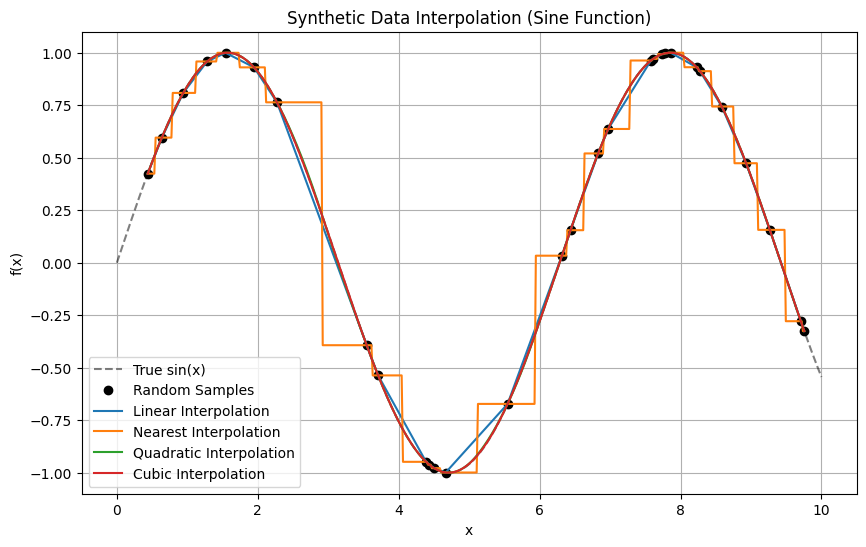

In [2]:

# Define the true sine function
def f(x):
    return np.sin(x)

# Generate the continuous function for reference
x_true = np.linspace(0, 10, 500)
y_true = f(x_true)

# Generate random samples from the domain
# Sorting is required for some interpolation methods
num_samples = 30
x_sampled = np.sort(rng.uniform(0, 10, num_samples))
y_sampled = f(x_sampled)

# Apply different interpolation methods
x_interp = np.linspace(x_sampled.min(), x_sampled.max(), 500)
methods = ['linear', 'nearest', 'quadratic', 'cubic']

plt.figure(figsize=(10, 6))
plt.plot(x_true, y_true, 'k--', label='True sin(x)', alpha=0.5)
plt.plot(x_sampled, y_sampled, 'ko', label='Random Samples', markersize=6)

# Iterate through methods and plot each one

for kind in methods:
    f_interp = interpolate.interp1d(x_sampled, y_sampled, kind=kind)
    plt.plot(x_interp, f_interp(x_interp), label=f'{kind.capitalize()} Interpolation')

plt.title('Synthetic Data Interpolation (Sine Function)')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid(True)
plt.savefig('8.1.1.png')
plt.show()

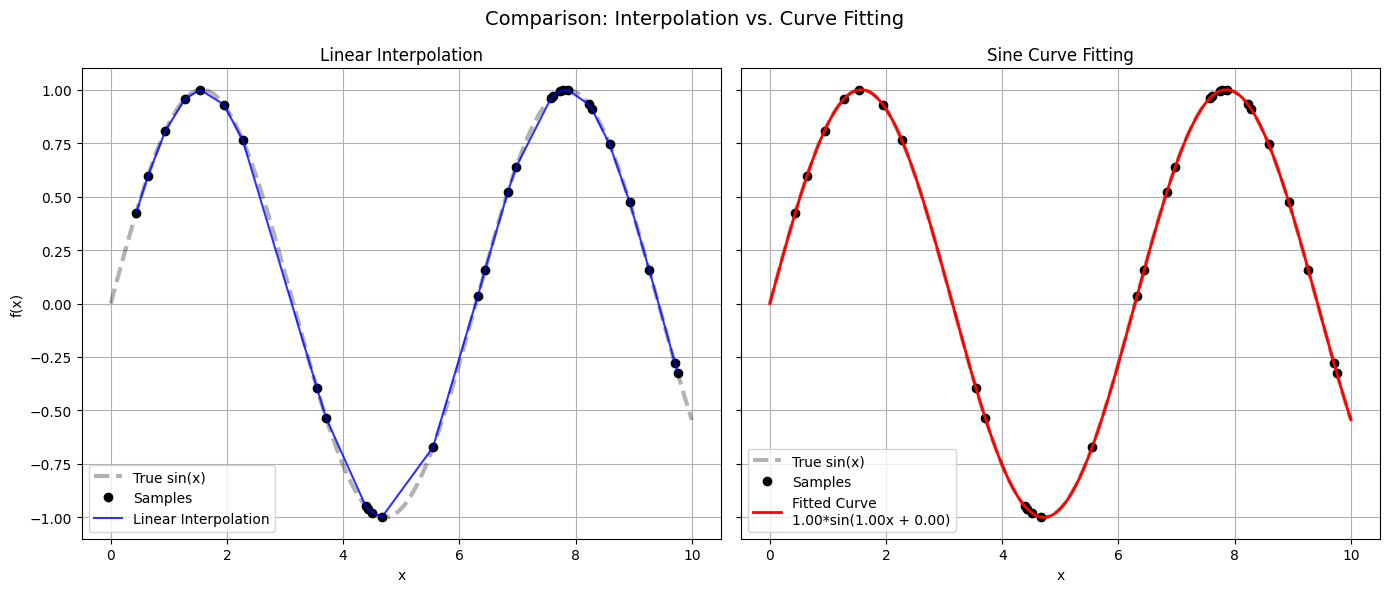

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from scipy.optimize import curve_fit

# Reproduce the exact same sampled points
rng = np.random.default_rng(42)

def f(x):
    return np.sin(x)

x_true = np.linspace(0, 10, 500)
y_true = f(x_true)

num_samples = 30
x_sampled = np.sort(rng.uniform(0, 10, num_samples))
y_sampled = f(x_sampled)

# Linear Interpolation
f_linear = interpolate.interp1d(x_sampled, y_sampled, kind='linear')
x_interp = np.linspace(x_sampled.min(), x_sampled.max(), 500)
y_linear = f_linear(x_interp)

# Curve Fitting
def sine_model(x, amplitude, frequency, phase, offset):
    return amplitude * np.sin(frequency * x + phase) + offset

initial_guess = [1.0, 1.0, 0.0, 0.0]
optimal_params, covariance = curve_fit(sine_model, x_sampled, y_sampled, p0=initial_guess)
y_fitted = sine_model(x_true, *optimal_params)

# Create Side-by-Side Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Plot 1: Cubic Interpolation
ax1.plot(x_true, y_true, 'k--', label='True sin(x)', alpha=0.3, linewidth=3)
ax1.plot(x_sampled, y_sampled, 'ko', label='Samples', markersize=6)
ax1.plot(x_interp, y_linear, 'b-', label='Linear Interpolation', alpha=0.8)
ax1.set_title('Linear Interpolation')
ax1.set_xlabel('x')
ax1.set_ylabel('f(x)')
ax1.legend()
ax1.grid(True)

# Plot 2: Curve Fitting
ax2.plot(x_true, y_true, 'k--', label='True sin(x)', alpha=0.3, linewidth=3)
ax2.plot(x_sampled, y_sampled, 'ko', label='Samples', markersize=6)
ax2.plot(x_true, y_fitted, 'r-', label=f'Fitted Curve\n{optimal_params[0]:.2f}*sin({optimal_params[1]:.2f}x + {optimal_params[2]:.2f})', linewidth=2)
ax2.set_title('Sine Curve Fitting')
ax2.set_xlabel('x')
ax2.legend()
ax2.grid(True)

plt.suptitle('Comparison: Interpolation vs. Curve Fitting', fontsize=14)
plt.tight_layout()
plt.savefig('8.1.2.png')
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%.

In [4]:
!wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [5]:
import pandas as pd
print(pd.__version__)

2.2.3


In [6]:
df = pd.read_csv('dow.txt', sep='\t')
df.head()

,12121.71
0,12136.44
1,12226.73
2,12221.93
3,12194.13
4,12283.85


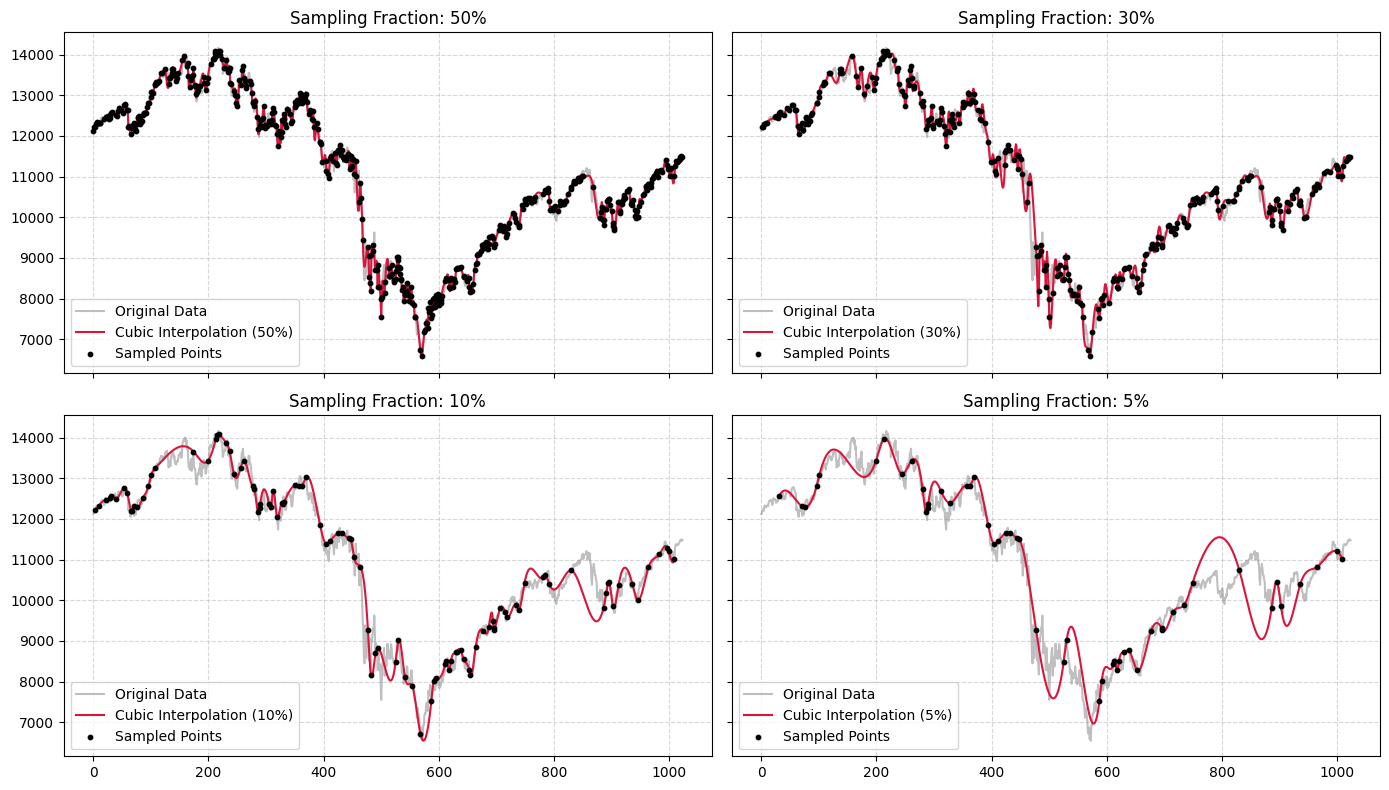

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define sampling fractions
sampling_fractions = [0.50, 0.30, 0.10, 0.05]

df_original = pd.read_csv("dow.txt", header=None, names=["value"])

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
axes = axes.flatten()


for i, frac in enumerate(sampling_fractions):
    # Randomly sample a fraction of observations and sort by original index
    sampled = df_original.sample(frac=frac, random_state=42).sort_index()

    # Reindex to full original length
    reconstructed = sampled.reindex(df_original.index)

    # Perform cubic spline interpolation
    reconstructed["cubic_interp"] = reconstructed["value"].interpolate(method="cubic")

    # Plot original vs reconstructed
    ax = axes[i]
    ax.plot(df_original.index, df_original["value"], color="gray", alpha=0.5, label="Original Data")
    ax.plot(reconstructed.index, reconstructed["cubic_interp"], color="crimson", linewidth=1.5, label=f"Cubic Interpolation ({int(frac*100)}%)")
    ax.scatter(sampled.index, sampled["value"], color="black", s=10, zorder=3, label="Sampled Points")

    ax.set_title(f"Sampling Fraction: {int(frac*100)}%")
    ax.legend(loc="lower left")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig('8.2.png')
plt.show()

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

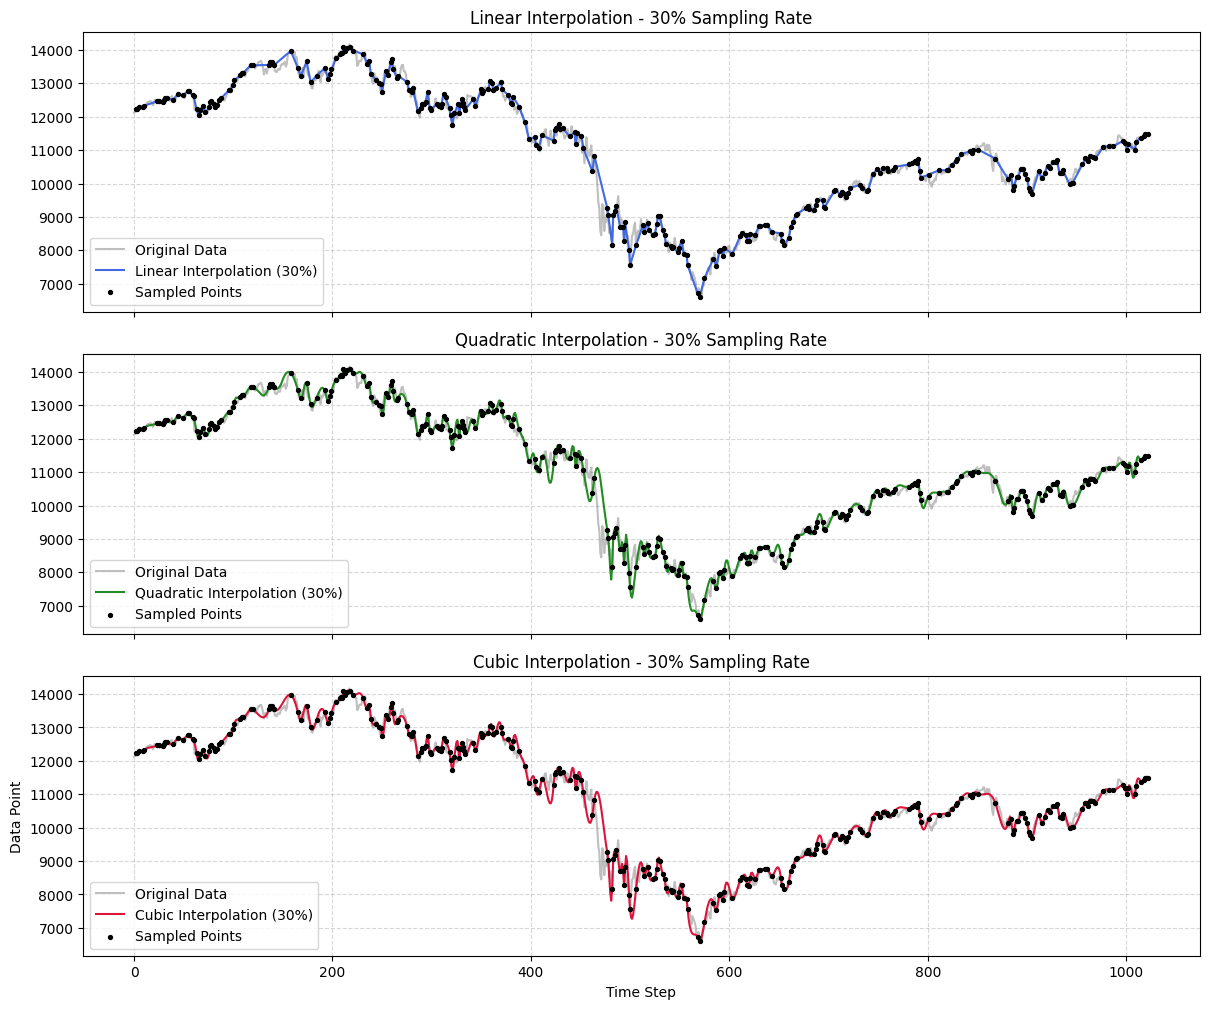

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df_original = pd.read_csv("dow.txt", header=None, names=["value"])

frac = 0.30
sampled = df_original.sample(frac=frac, random_state=42).sort_index()

# this is for the placeholder gaps that the interpolation methods will fill
reconstructed = sampled.reindex(df_original.index)

# Perform the 3 interpolation methods
reconstructed["linear_interp"] = reconstructed["value"].interpolate(method="linear")
reconstructed["quadratic_interp"] = reconstructed["value"].interpolate(method="quadratic")
reconstructed["cubic_interp"] = reconstructed["value"].interpolate(method="cubic")

# Define methods and colors to loop over
methods = [
    ("linear_interp", "Linear Interpolation", "royalblue"),
    ("quadratic_interp", "Quadratic Interpolation", "forestgreen"),
    ("cubic_interp", "Cubic Interpolation", "crimson")
]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, sharey=True)

# Loop over each interpolation method and plot on its corresponding axis
for i, (col, title, color) in enumerate(methods):
    ax = axes[i]
    ax.plot(df_original.index, df_original["value"], color="gray", alpha=0.5, label="Original Data")
    ax.plot(reconstructed.index, reconstructed[col], color=color, linewidth=1.5, label=f"{title} (30%)")
    ax.scatter(sampled.index, sampled["value"], color="black", s=8, zorder=3, label="Sampled Points")

    ax.set_title(f"{title} - 30% Sampling Rate")
    ax.legend(loc="lower left")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig('8.3.png')
plt.xlabel("Time Step")
plt.ylabel("Data Point")
plt.show()

### Problem  code summary


The code takes a known sine function (and later the Dow Jones series), randomly keeps only some of the points, and tries to rebuild the full curve from them. For the sine data, I used `interp1d` to compare nearest, linear, quadratic, and cubic interpolation, and then used `curve_fit` to fit a sine model with amplitude, frequency, phase, and offset to the same samples. For the Dow data, I randomly sampled a fraction of the rows, put them back at their original indices with `reindex` so the missing days become NaN, and let pandas' `interpolate` fill the gaps, using cubic at 50%, 30%, 10%, and 5% and then linear, quadratic, and cubic at 30%.